<a href="https://colab.research.google.com/github/Thu0412/Machine-Learning/blob/main/Regression/Tuan1_NguyenTranMinhThu_BaiTapOLop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BÀI TẬP Ở LỚP
- Bài 1. Giả sử có một tập dữ liệu giả định với các cột Diện tích nhà (m2) và Giá bán (triệu VND).
1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên Diện tích nhà.
2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.

In [11]:
# Thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [12]:
print ("1. Mô hình hồi quy tuyến tính đơn giản")
np.random.seed (42)
n_samples=100

1. Mô hình hồi quy tuyến tính đơn giản


In [13]:
# Tạo dữ liệu giả định
dien_tich= np.random.uniform (30, 150, n_samples) # Diện tích từ 30m2 đến 150m2

In [14]:
# Công thức giả định: Giá bán = 30 * Dien tich + 200 + Nhiễu
nhieu = np.random.normal (0, 150, n_samples)
gia_ban = 30 * dien_tich + 200 + nhieu
df_simple = pd.DataFrame ({'Dien tich': dien_tich, 'Gia ban': gia_ban})


In [15]:
# Chia tập dữ liệu
X_train = df_simple[['Dien tich']]
y_train = df_simple['Gia ban']
X_train, X_test, y_train, y_test = train_test_split (X_train, y_train, test_size=0.2, random_state=42)

In [16]:
# Huấn luyện mô hình đơn giản
model_simple = LinearRegression()
model_simple.fit (X_train, y_train)

LinearRegression()

In [17]:
# Dự đoán và đánh giá
y_pred = model_simple.predict (X_test)
print (f"Hệ số góc (Slope): {model_simple.coef_}")
print (f"Hệ số chặn (Intercept): {model_simple.intercept_}")
print (f"MSE: {mean_squared_error (y_test, y_pred)}")
print (f"R2 Score: {r2_score (y_test, y_pred)}\n")

Hệ số góc (Slope): [29.49830914]
Hệ số chặn (Intercept): 236.48772360776456
MSE: 14708.23905863252
R2 Score: 0.9879579534356216



In [18]:
print ("2. Thêm nhiều dữ liệu và tăng độ nhiễu")

2. Thêm nhiều dữ liệu và tăng độ nhiễu


In [20]:
n_samples_large=1000
Dien_tich_large= np.random.uniform (30, 150, n_samples_large)
nhieu_large= np.random.normal (0, 150, n_samples_large) # Độ nhiễu tăng từ 150 lên 500
gia_ban_large= 30 * Dien_tich_large + 200 + nhieu_large

In [21]:
X_train = Dien_tich_large.reshape (-1, 1)
y_train = gia_ban_large
X_train, X_test, y_train, y_test = train_test_split (X_train, y_train, test_size=0.2, random_state=42)

In [22]:
model_large = LinearRegression()
model_large.fit (X_train, y_train)

LinearRegression()

In [23]:
# Dự đoán và đánh giá mô hình sau khi thêm dữ liệu và tăng độ nhiễu
y_pred_1 = model_large.predict (X_test)
print (f"Hệ số góc (Slope): {model_large.coef_}")
print (f"Hệ số chặn (Intercept): {model_large.intercept_}")
print (f"MSE: {mean_squared_error (y_test, y_pred_1)}")
print (f"R2 Score: {r2_score (y_test, y_pred_1)}")

Hệ số góc (Slope): [30.11005278]
Hệ số chặn (Intercept): 200.38990180024302
MSE: 19481.21129649096
R2 Score: 0.9828427866308665


In [24]:
print ("3. Thêm các biến đầu vào khác - Hồi quy tuyến tính đa biến")

3. Thêm các biến đầu vào khác - Hồi quy tuyến tính đa biến


In [25]:
# Thêm biến số phòng ngủ (từ 1 đến 5 phòng)
so_phong_ngu = np.random.randint (1, 6, n_samples_large)
# Thêm biến khoảng cách đến trung tâm (km)
khoang_cach = np.random.uniform (1, 20, n_samples_large)

In [26]:
# Công thức giả định mới: 25 * DienTich + 150 * SoPhongNgu - 50 * KhoangCach + 300 + Nhiễu
nhieu = np.random.normal (0, 100, n_samples_large)
gia_ban_multi = 25 * Dien_tich_large + 150*so_phong_ngu - 50*khoang_cach + 300 + nhieu

In [27]:
df_multi = pd.DataFrame({
    'DienTich': Dien_tich_large,
    'SoPhongNgu': so_phong_ngu,
    'KhoangCach': khoang_cach,
    'GiaBan': gia_ban_multi
})


In [29]:
# Chia tập dữ liệu
X_m = df_multi[['DienTich', 'SoPhongNgu', 'KhoangCach']]
y_m = df_multi['GiaBan']
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_m, y_m, test_size=0.2, random_state=42)

In [30]:
# Huấn luyện mô hình
model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

LinearRegression()

In [31]:
y_pred_m = model_multi.predict(X_test_m)

print("Hệ số hồi quy (Coefficients): ", model_multi.coef_)
print("Hệ số chặn (Intercept): ", model_multi.intercept_)
print(f"R2 Score (Đa biến): {r2_score(y_test_m, y_pred_m):.2f}")


Hệ số hồi quy (Coefficients):  [ 25.11695433 153.38595435 -51.255187  ]
Hệ số chặn (Intercept):  303.178147639946
R2 Score (Đa biến): 0.98


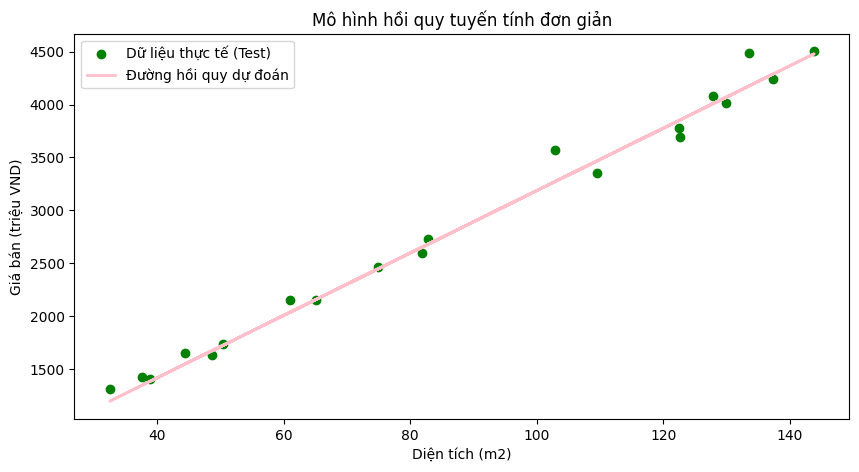

In [40]:
# Vẽ biểu đồ trực quan hóa kết quả cho mô hình đơn giản 1
# Chia lại tập dữ liệu cho mô hình đơn giản để lấy đúng X_test và y_test ban đầu
X_simple = df_simple[['Dien tich']]
y_simple = df_simple['Gia ban']
_, X_test_simple, _, y_test_simple = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

# Dự đoán lại bằng model_simple đã huấn luyện
y_pred_simple = model_simple.predict(X_test_simple)

plt.figure(figsize=(10, 5))
plt.scatter(X_test_simple, y_test_simple, color='green', label='Dữ liệu thực tế (Test)')
plt.plot(X_test_simple, y_pred_simple, color='pink', linewidth=2, label='Đường hồi quy dự đoán')
plt.xlabel('Diện tích (m2)')
plt.ylabel('Giá bán (triệu VND)')
plt.title('Mô hình hồi quy tuyến tính đơn giản')
plt.legend()
plt.show()

- Bài 2. Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI
- Giả sử có một tập dữ liệu với các thông tin sau:
- + BMI: Chỉ số khối cơ thể của bệnh nhân (Body Mass Index)
- + Mắc bệnh: Nhãn mục tiêu là 1 nếu bệnh nhân mắc bệnh và 0 nếu không mắc bệnh.
- Yêu cầu:
1. Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn Mắc bệnh dựa trên mối liên hệ logic (BMI cao có thể dẫn đến khả năng mắc bệnh cao hơn).
2. Sử dụng thư viện phù hợp (HD: scikit-learn) để xây dựng một mô hình hồi quy logistic.
3. Huấn luyện mô hình trên tập dữ liệu mẫu.
4. Dự đoán xác suất và nhãn mắc bệnh cho một tập dữ liệu kiểm tra.
5. Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn.
6. Trực quan hóa dữ liệu và đường hồi quy logistic.

In [42]:
# Tạo dữ liệu mẫu giả định
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)
n = 300
bmi = np.random.normal(loc=25, scale=5, size=n).clip(15, 45)

# Xác suất mắc bệnh thật tăng theo BMI (sigmoid)
p_true = 1 / (1 + np.exp(-0.6 * (bmi - 27)))
benh = np.random.binomial(1, p_true)

df = pd.DataFrame({'BMI': bmi.round(1), 'Mac_benh': benh})
print(df.head())
print(df['Mac_benh'].value_counts())

    BMI  Mac_benh
0  27.5         1
1  24.3         0
2  28.2         0
3  32.6         1
4  23.8         1
Mac_benh
0    191
1    109
Name: count, dtype: int64


In [43]:
# Chia tập dữ liệu và huấn luyện mô hình
X = df[['BMI']]
y = df['Mac_benh']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression()
model.fit(X_train, y_train)

print('Hệ số (w):', model.coef_[0][0])
print('Hệ số chặn (b):', model.intercept_[0])

Hệ số (w): 0.4898184664956948
Hệ số chặn (b): -13.193555036473988


In [45]:
# Dự đoán
y_proba = model.predict_proba(X_test)[:, 1]   # xác suất mắc bệnh
y_pred = model.predict(X_test)                # nhãn dự đoán (ngưỡng 0.5)

ket_qua = pd.DataFrame({
    'BMI': X_test['BMI'].values,
    'Xac_suat_mac_benh': y_proba.round(3),
    'Du_doan': y_pred,
    'Thuc_te': y_test.values
})
ket_qua.head(10)

,BMI,Xac_suat_mac_benh,Du_doan,Thuc_te
0,26.7,0.471,0,0
1,18.7,0.017,0,0
2,27.1,0.520,1,0
3,22.5,0.102,0,0
4,24.2,0.208,0,0
5,27.9,0.616,1,0
6,25.9,0.376,0,0
7,17.4,0.009,0,0
8,32.9,0.949,1,1
9,23.5,0.157,0,0


Độ chính xác (Accuracy): 76.67%
Ma trận nhầm lẫn:
 [[31  7]
 [ 7 15]]
              precision    recall  f1-score   support

  Không bệnh       0.82      0.82      0.82        38
    Mắc bệnh       0.68      0.68      0.68        22

    accuracy                           0.77        60
   macro avg       0.75      0.75      0.75        60
weighted avg       0.77      0.77      0.77        60



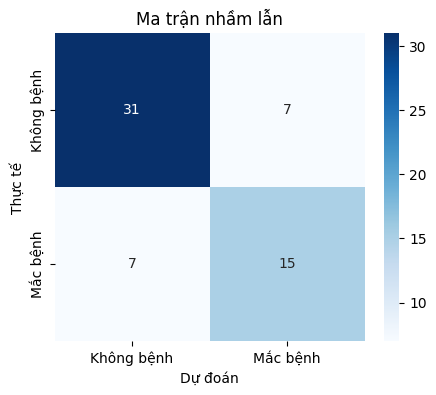

In [46]:
# Đánh giá
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f'Độ chính xác (Accuracy): {acc:.2%}')
print('Ma trận nhầm lẫn:\n', cm)
print(classification_report(y_test, y_pred, target_names=['Không bệnh', 'Mắc bệnh']))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Không bệnh', 'Mắc bệnh'],
            yticklabels=['Không bệnh', 'Mắc bệnh'])
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title('Ma trận nhầm lẫn')
plt.show()

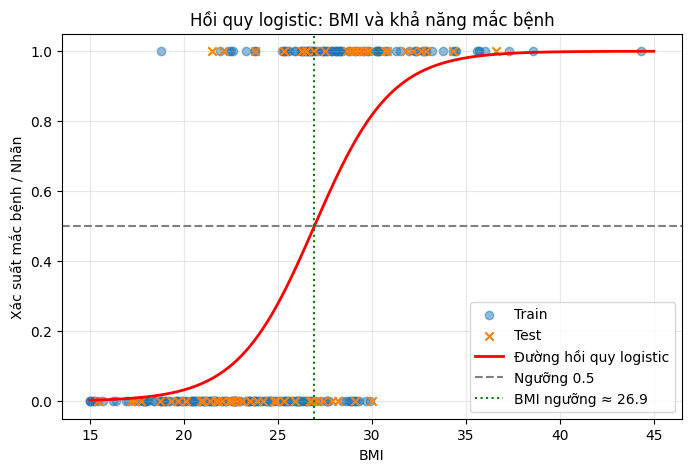

In [47]:
# Vẽ biểu đồ trực quan hóa kết quả
bmi_range = np.linspace(15, 45, 300).reshape(-1, 1)
bmi_range_df = pd.DataFrame(bmi_range, columns=['BMI'])
prob_curve = model.predict_proba(bmi_range_df)[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(X_train['BMI'], y_train, c='tab:blue', alpha=0.5, label='Train')
plt.scatter(X_test['BMI'], y_test, c='tab:orange', marker='x', label='Test')
plt.plot(bmi_range, prob_curve, 'r-', linewidth=2, label='Đường hồi quy logistic')
plt.axhline(0.5, color='gray', linestyle='--', label='Ngưỡng 0.5')

# BMI tại ngưỡng quyết định: w*x + b = 0
nguong_bmi = -model.intercept_[0] / model.coef_[0][0]
plt.axvline(nguong_bmi, color='green', linestyle=':', label=f'BMI ngưỡng ≈ {nguong_bmi:.1f}')

plt.xlabel('BMI')
plt.ylabel('Xác suất mắc bệnh / Nhãn')
plt.title('Hồi quy logistic: BMI và khả năng mắc bệnh')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- Bài 3. Hãy chọn 1 bộ dữ liệu tùy ý (HD: có thể tham khảo trên các trang mạng, ví dụ  như Kaggle) và thực hiện các bước cần thiết để có được mô hình hồi quy ứng với bộ dữ liệu đã chọn.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [49]:
df = pd.read_csv('simplelinearregression.csv')

In [50]:
print (df.head())

   Age  Premium
0   18    10000
1   22    15000
2   23    18000
3   26    21000
4   28    24000


In [51]:
print (df.isnull().sum())

Age        0
Premium    0
dtype: int64


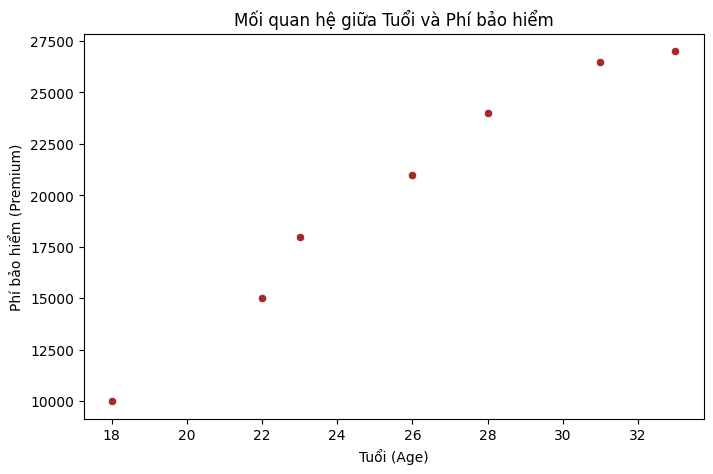

In [52]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='Premium', color='brown')
plt.title('Mối quan hệ giữa Tuổi và Phí bảo hiểm')
plt.xlabel('Tuổi (Age)')
plt.ylabel('Phí bảo hiểm (Premium)')
plt.show()

In [53]:
# Chia tập dữ liệu
# Tách biến X và y
X = df[['Age']]
y = df['Premium']

# Chia dữ liệu theo tỷ lệ 80% Huấn luyện - 20% Kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [54]:
# 1. Khởi tạo và huấn luyện mô hình Hồi quy tuyến tính
model_premium = LinearRegression()
model_premium.fit(X_train, y_train)

LinearRegression()

In [55]:
# 2. Dự đoán trên tập kiểm tra
y_pred_premium = model_premium.predict(X_test)

# Hiển thị hệ số hồi quy
print(f"Hệ số góc (Slope - Coefficient): {model_premium.coef_[0]:.2f}")
print(f"Hệ số chặn (Intercept): {model_premium.intercept_:.2f}")

Hệ số góc (Slope - Coefficient): 942.68
Hệ số chặn (Intercept): -3283.44


In [56]:
# 3. Đánh giá hiệu suất của mô hình
mae = mean_absolute_error(y_test, y_pred_premium)
mse = mean_squared_error(y_test, y_pred_premium)
r2 = r2_score(y_test, y_pred_premium)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R2 Score: {r2:.4f}")

Mean Absolute Error (MAE): 3070.06
Mean Squared Error (MSE): 9803085.32
R2 Score: -0.5685


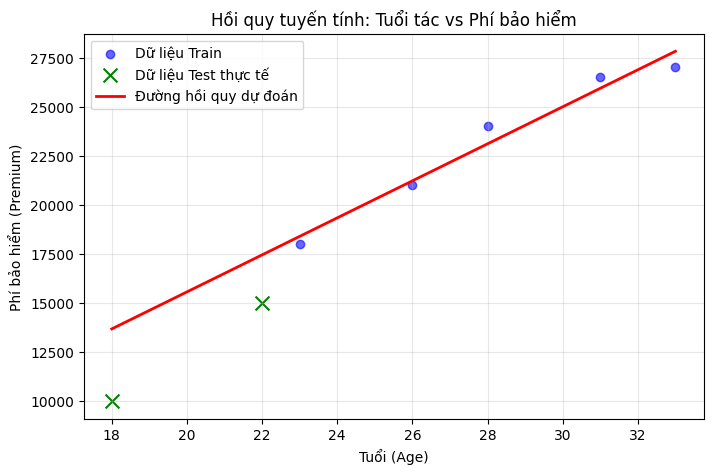

In [57]:
# 4. Trực quan hóa kết quả thực tế vs Dự đoán của mô hình
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.6, label='Dữ liệu Train')
plt.scatter(X_test, y_test, color='green', marker='x', s=100, label='Dữ liệu Test thực tế')
plt.plot(X, model_premium.predict(X), color='red', linewidth=2, label='Đường hồi quy dự đoán')

plt.title('Hồi quy tuyến tính: Tuổi tác vs Phí bảo hiểm')
plt.xlabel('Tuổi (Age)')
plt.ylabel('Phí bảo hiểm (Premium)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()